# 14 — Explore the generated entity evidence

Inspect the saved **GLiNER predictions and unchanged seed rules on the identical 100 CVs + 100 JDs**. The completed transformer run contains 1,832 spans; the same-population rules contain 731. Notebook 11's 1,000+1,000 development run is a different population and its totals are not used here.

This notebook loads the run named by the committed aggregate record, verifies its artifacts, sample identity and source offsets, and regenerates rules on those exact training IDs. **It does not rerun neural inference.** Charts and real bounded examples describe predictions, not extraction accuracy or screening quality.

The [EDA plan](../plan/2026-10-06-entity-extraction-eda/README.md) authorizes inspection of real extracted text. Contact redaction runs before displaying examples; full resumes/JDs are never displayed. Original evidence offsets remain untouched.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from candidate_screener.config import OUTPUT
from candidate_screener.annotation.redact import assert_clean, redact_text
from candidate_screener.extraction.eda import load_analysis, analyze, bounded_examples, save_tables
from candidate_screener.extraction.eda_plots import save_charts

# The run is discovered from this existing record, not an inference request.
METRICS_PATH = OUTPUT / "extraction" / "transformer-metrics.json"
EDA_OUTPUT = OUTPUT / "extraction" / "eda"


Matplotlib is building the font cache; this may take a moment.


## 1. Run inventory and evidence schema

Both methods retain field-relative `start`/`end`, original `surface`, `label`, source/document provenance, extraction method/version and heuristic `context_status`. Rules have null confidence; GLiNER confidence is a raw uncalibrated score. Neither is a proficiency or fit judgement. Canonical IDs are not evaluated here.

In [2]:
analysis = load_analysis(METRICS_PATH)
tables = analyze(analysis)
population = analysis["documents"].groupby("doc_type").size().to_dict()
print(json.dumps({"run_id": analysis["run_id"], "documents": population,
                  "entity_counts": {"GLiNER": len(analysis["neural"]), "rules": len(analysis["rules"])},
                  "checks": analysis["validation"]}, indent=2))


{
  "run_id": "2c591cc8bff7fc9e7189-20261005T164947399919Z",
  "documents": {
    "cv": 100,
    "jd": 100
  },
  "entity_counts": {
    "GLiNER": 1832,
    "rules": 731
  },
  "checks": {
    "artifact_hashes": true,
    "sample_identity": true,
    "exact_source_spans": true,
    "rule_comparison": "Rules regenerated on identical sampled IDs; no neural reinference"
  }
}


In [3]:
provenance = analysis["provenance"]
print(json.dumps({"model": provenance["model"]["model_id"], "revision": provenance["model"]["revision"],
                  "region": provenance["region"], "seed": provenance["seed"], "threshold": provenance["threshold"]}, indent=2))
charts = save_charts(tables, analysis["neural"], EDA_OUTPUT)

aggregate_tables = save_tables(tables, EDA_OUTPUT)


{
  "model": "urchade/gliner_small-v2.1",
  "revision": "4e091416cf7c3481db542c2a3d26156916f3a47f",
  "region": "train",
  "seed": 0,
  "threshold": 0.5
}


## 2. Entity counts and document coverage

Counts measure extracted spans, so a document mentioning a tool several times can contribute several spans. Coverage measures distinct documents containing a label, divided by **all 100 documents of that source type**, including documents with no entities. The larger neural count is a broader set of predictions, not evidence of better recall.

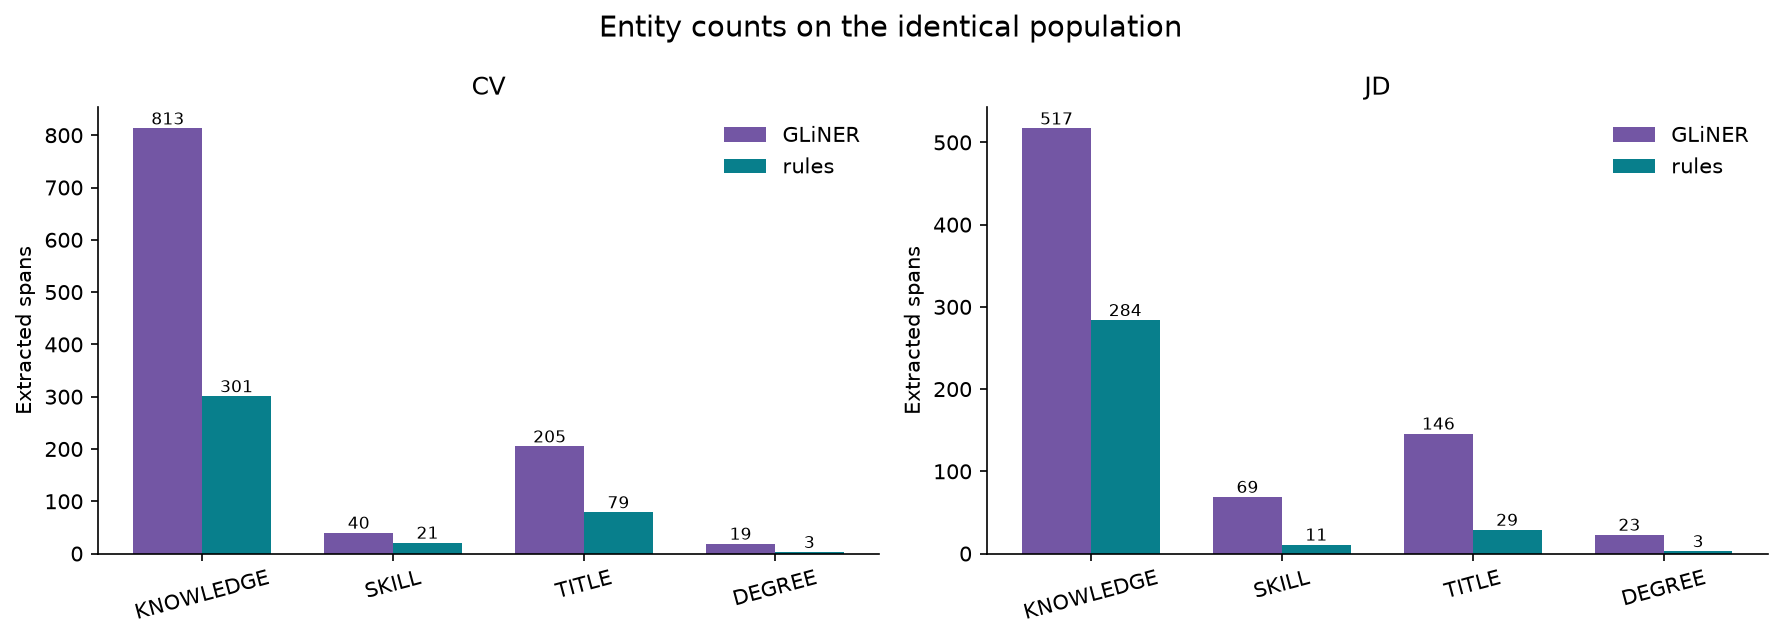

In [4]:
display(Image(filename=charts["counts"]))

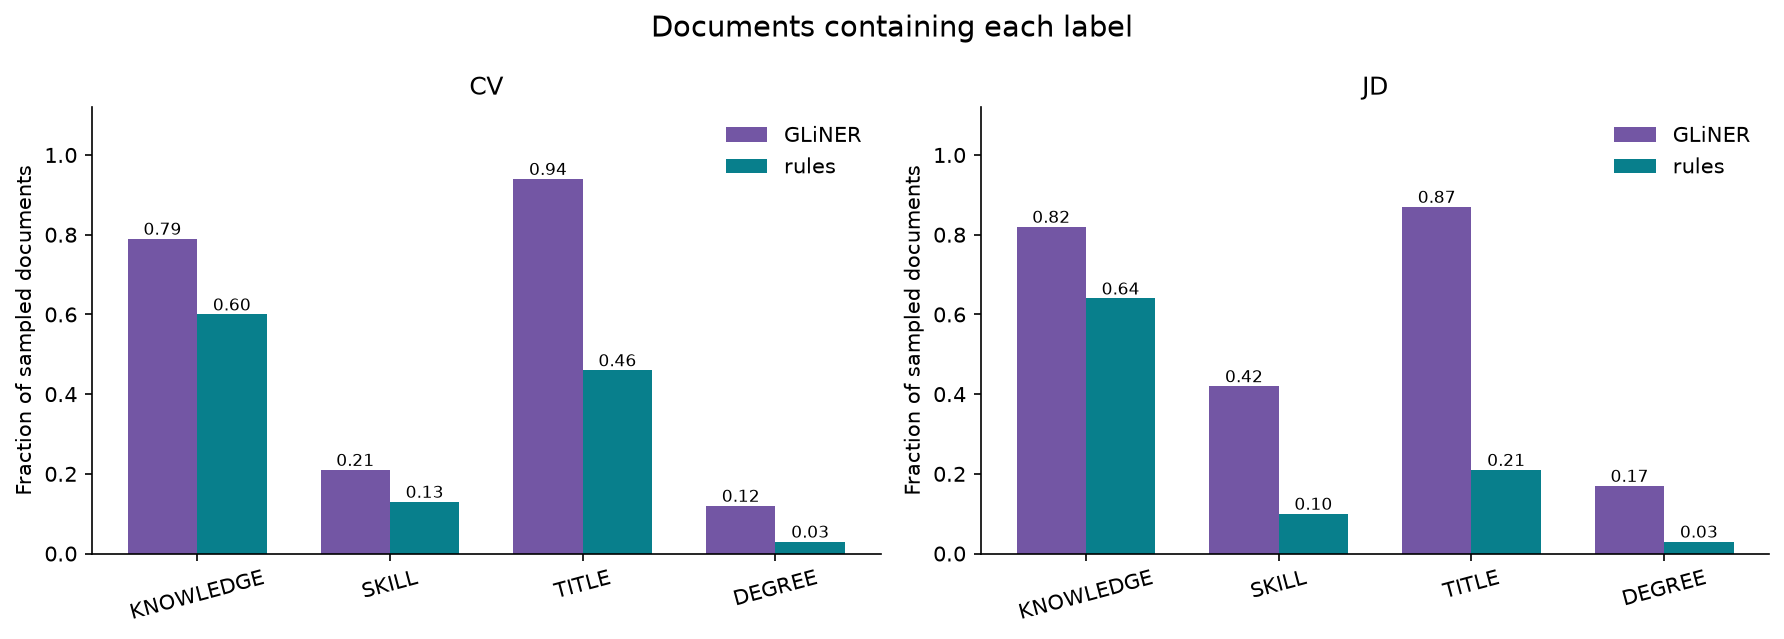

In [5]:
display(Image(filename=charts["coverage"]))

## 3. Per-document counts and label co-occurrence

The distributions retain zero-entity documents for both methods. Co-occurrence counts documents containing both labels, not the number of span pairs. Each diagonal gives the number of documents containing that label; off-diagonal cells use the same source population.

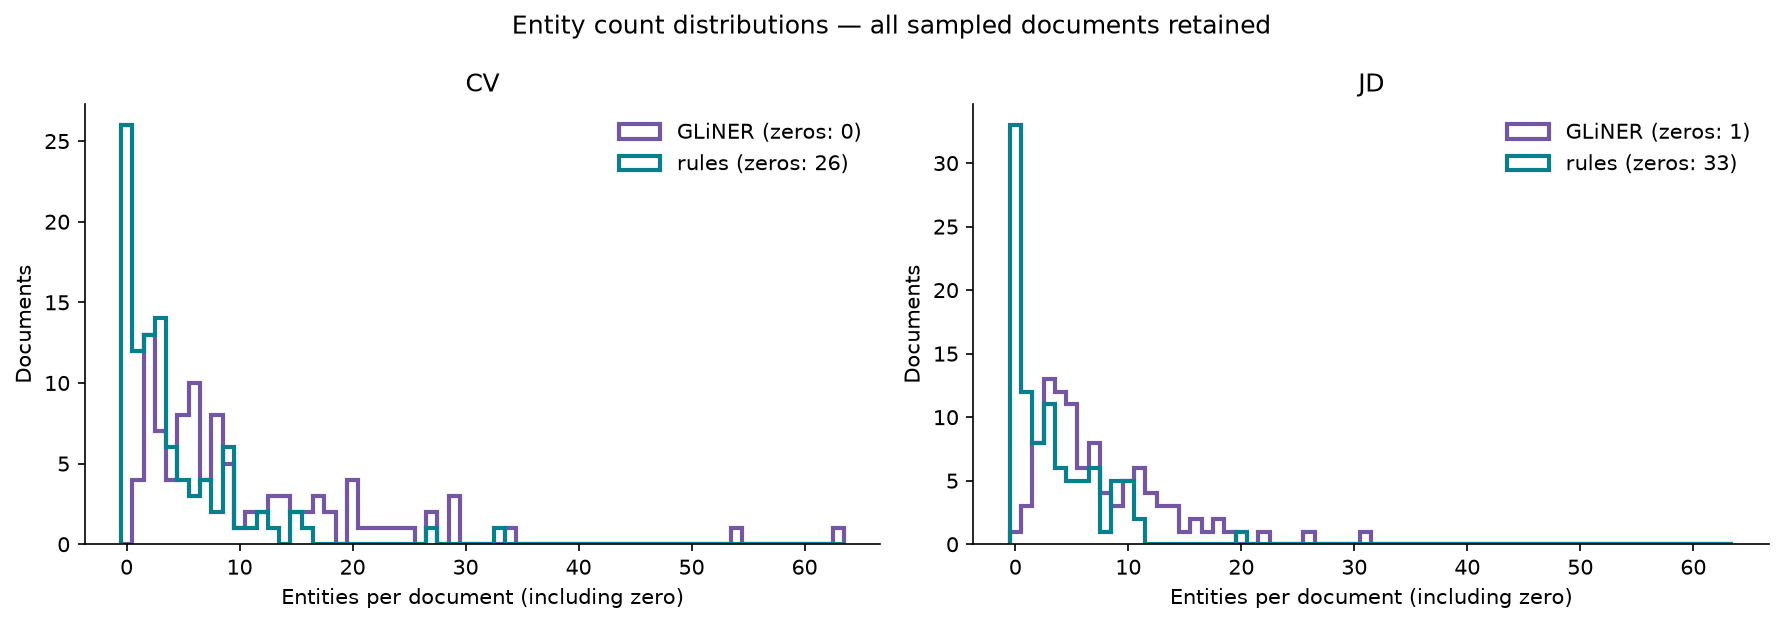

In [6]:
display(Image(filename=charts["document_counts"]))

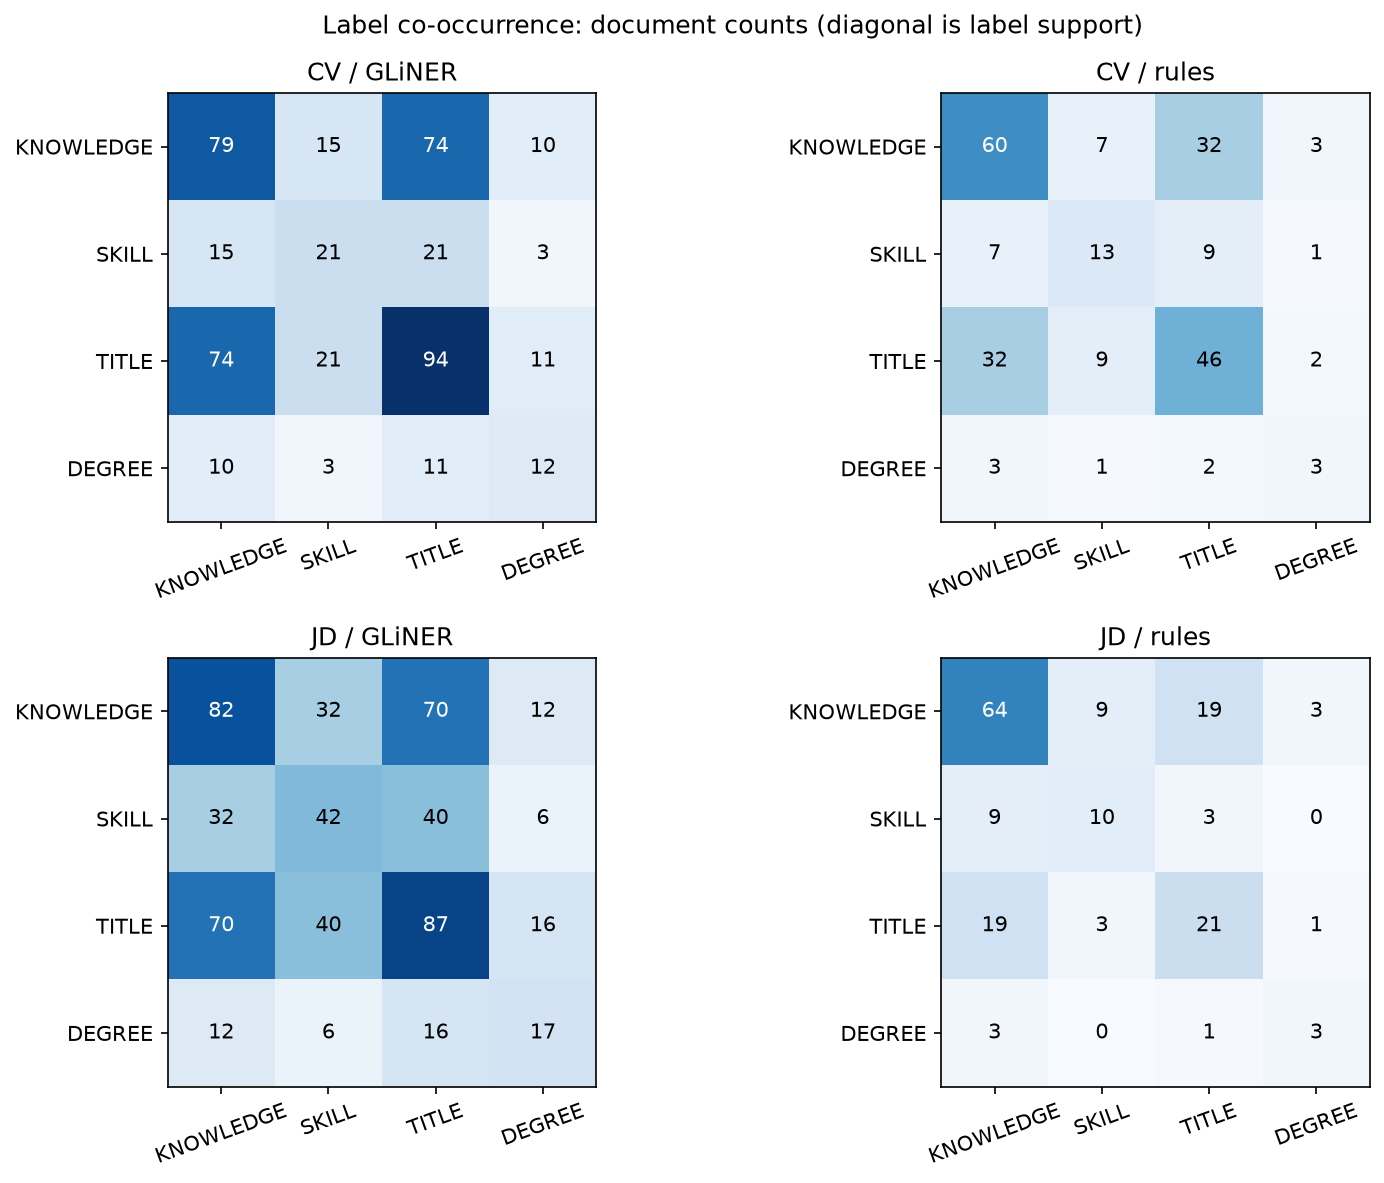

In [7]:
display(Image(filename=charts["cooccurrence"]))

## 4. Actual mention strings

These charts show the five most frequent real extracted strings in each label/source combination. Case folding groups spelling-case variants for this descriptive view. It does **not** establish synonym equivalence, disambiguation or canonical linking. Neural phrases may be longer or more specific than the fixed seed vocabulary.

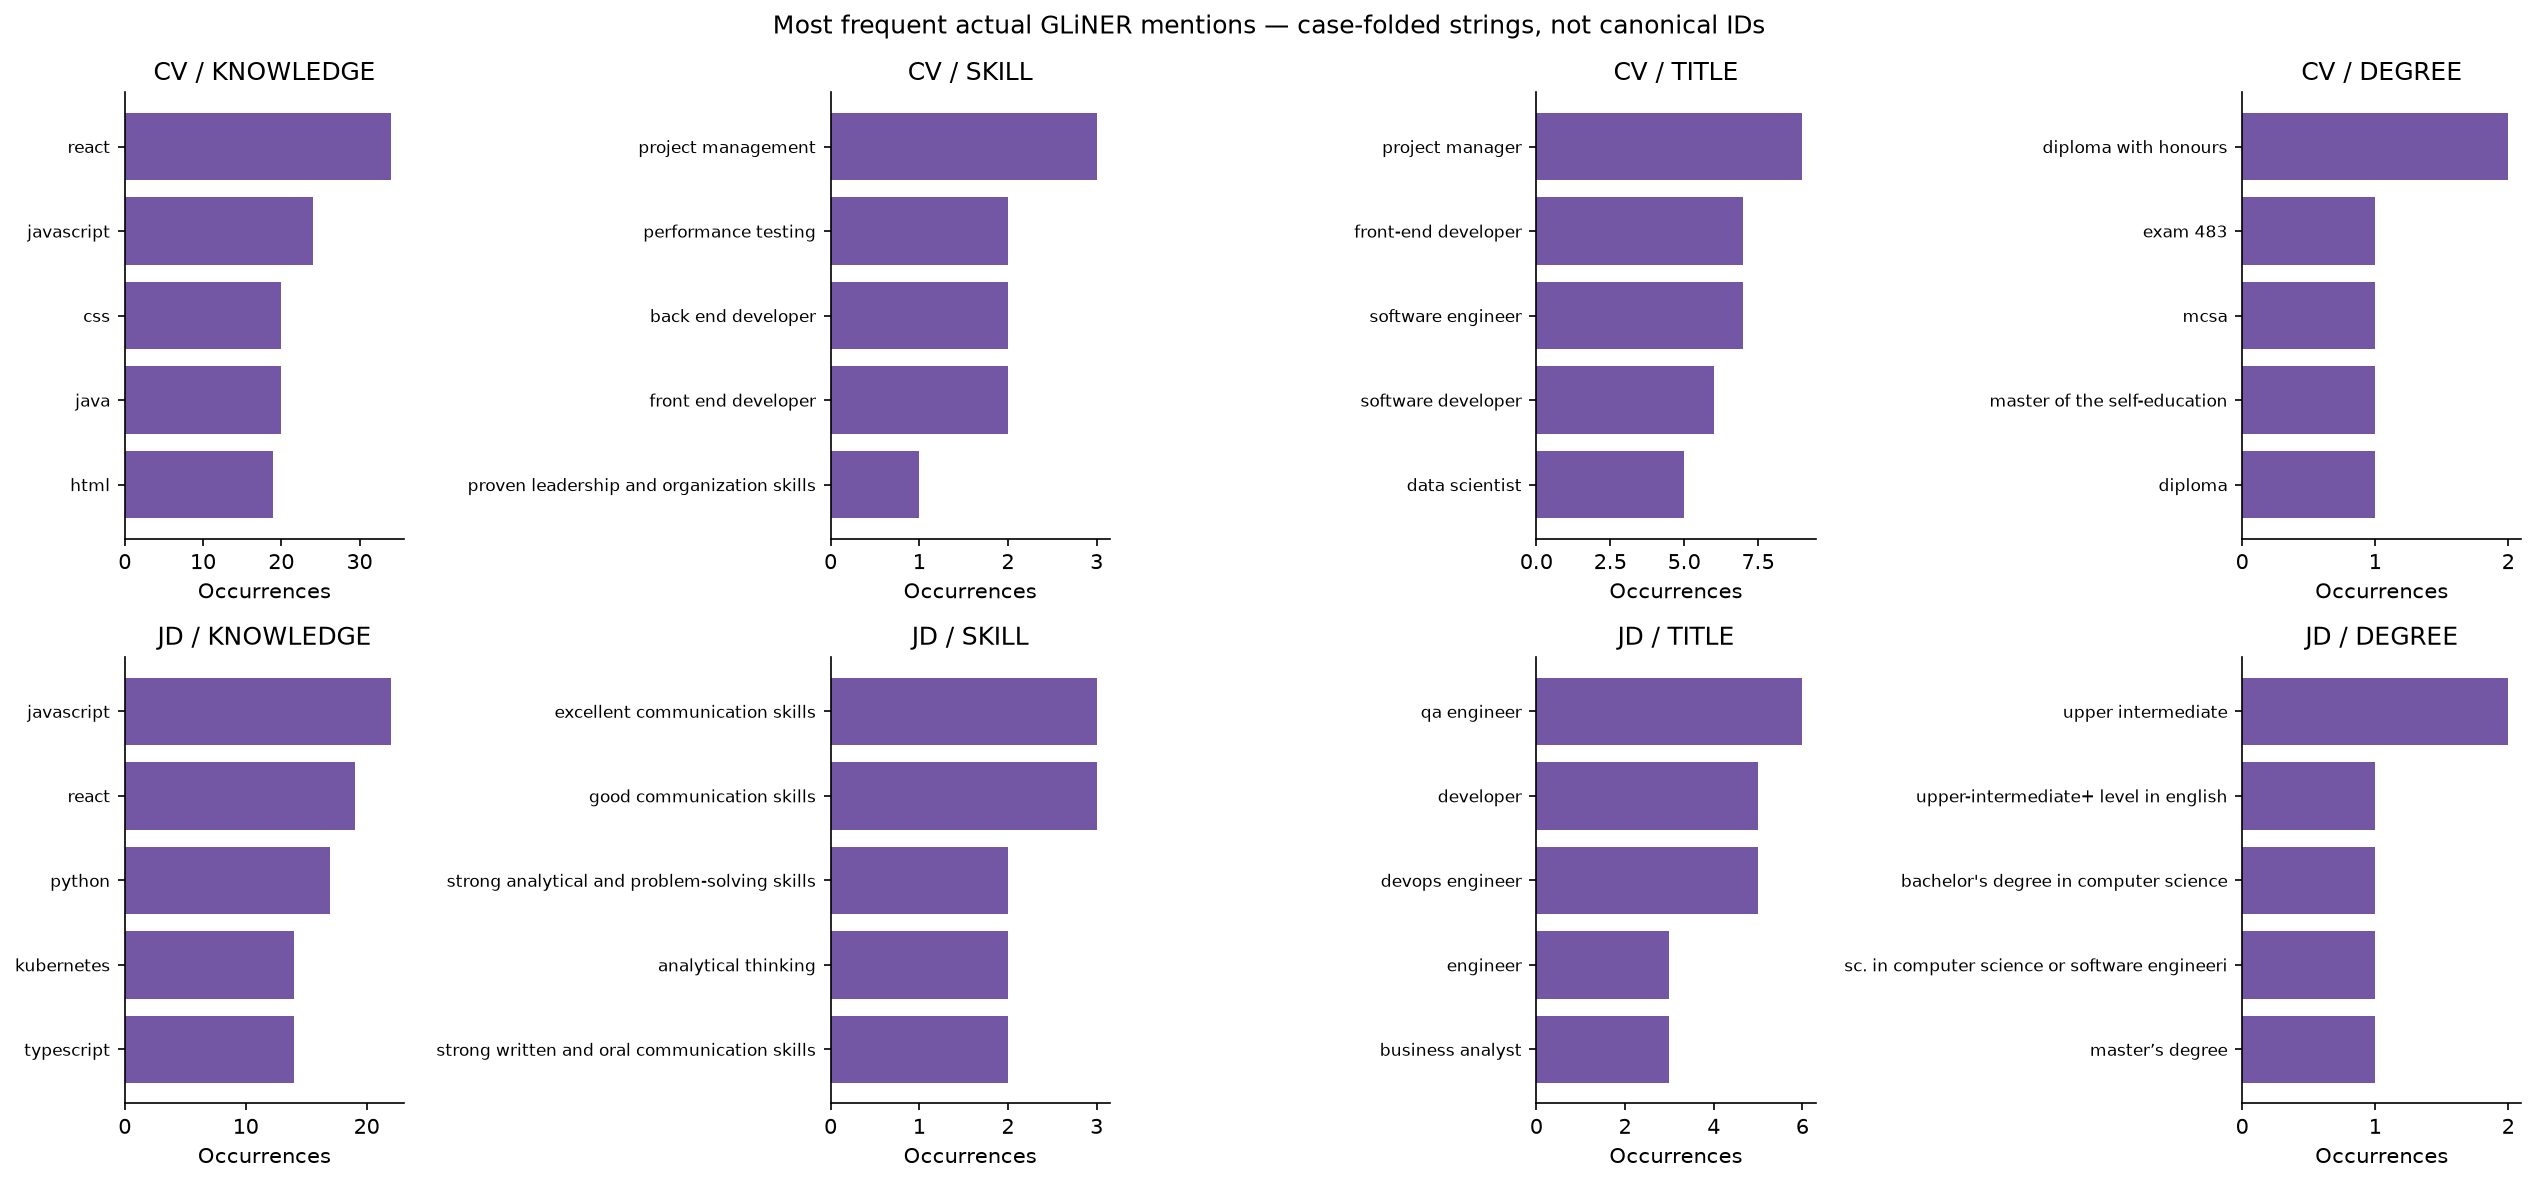

In [8]:
display(Image(filename=charts["mentions-GLiNER"]))

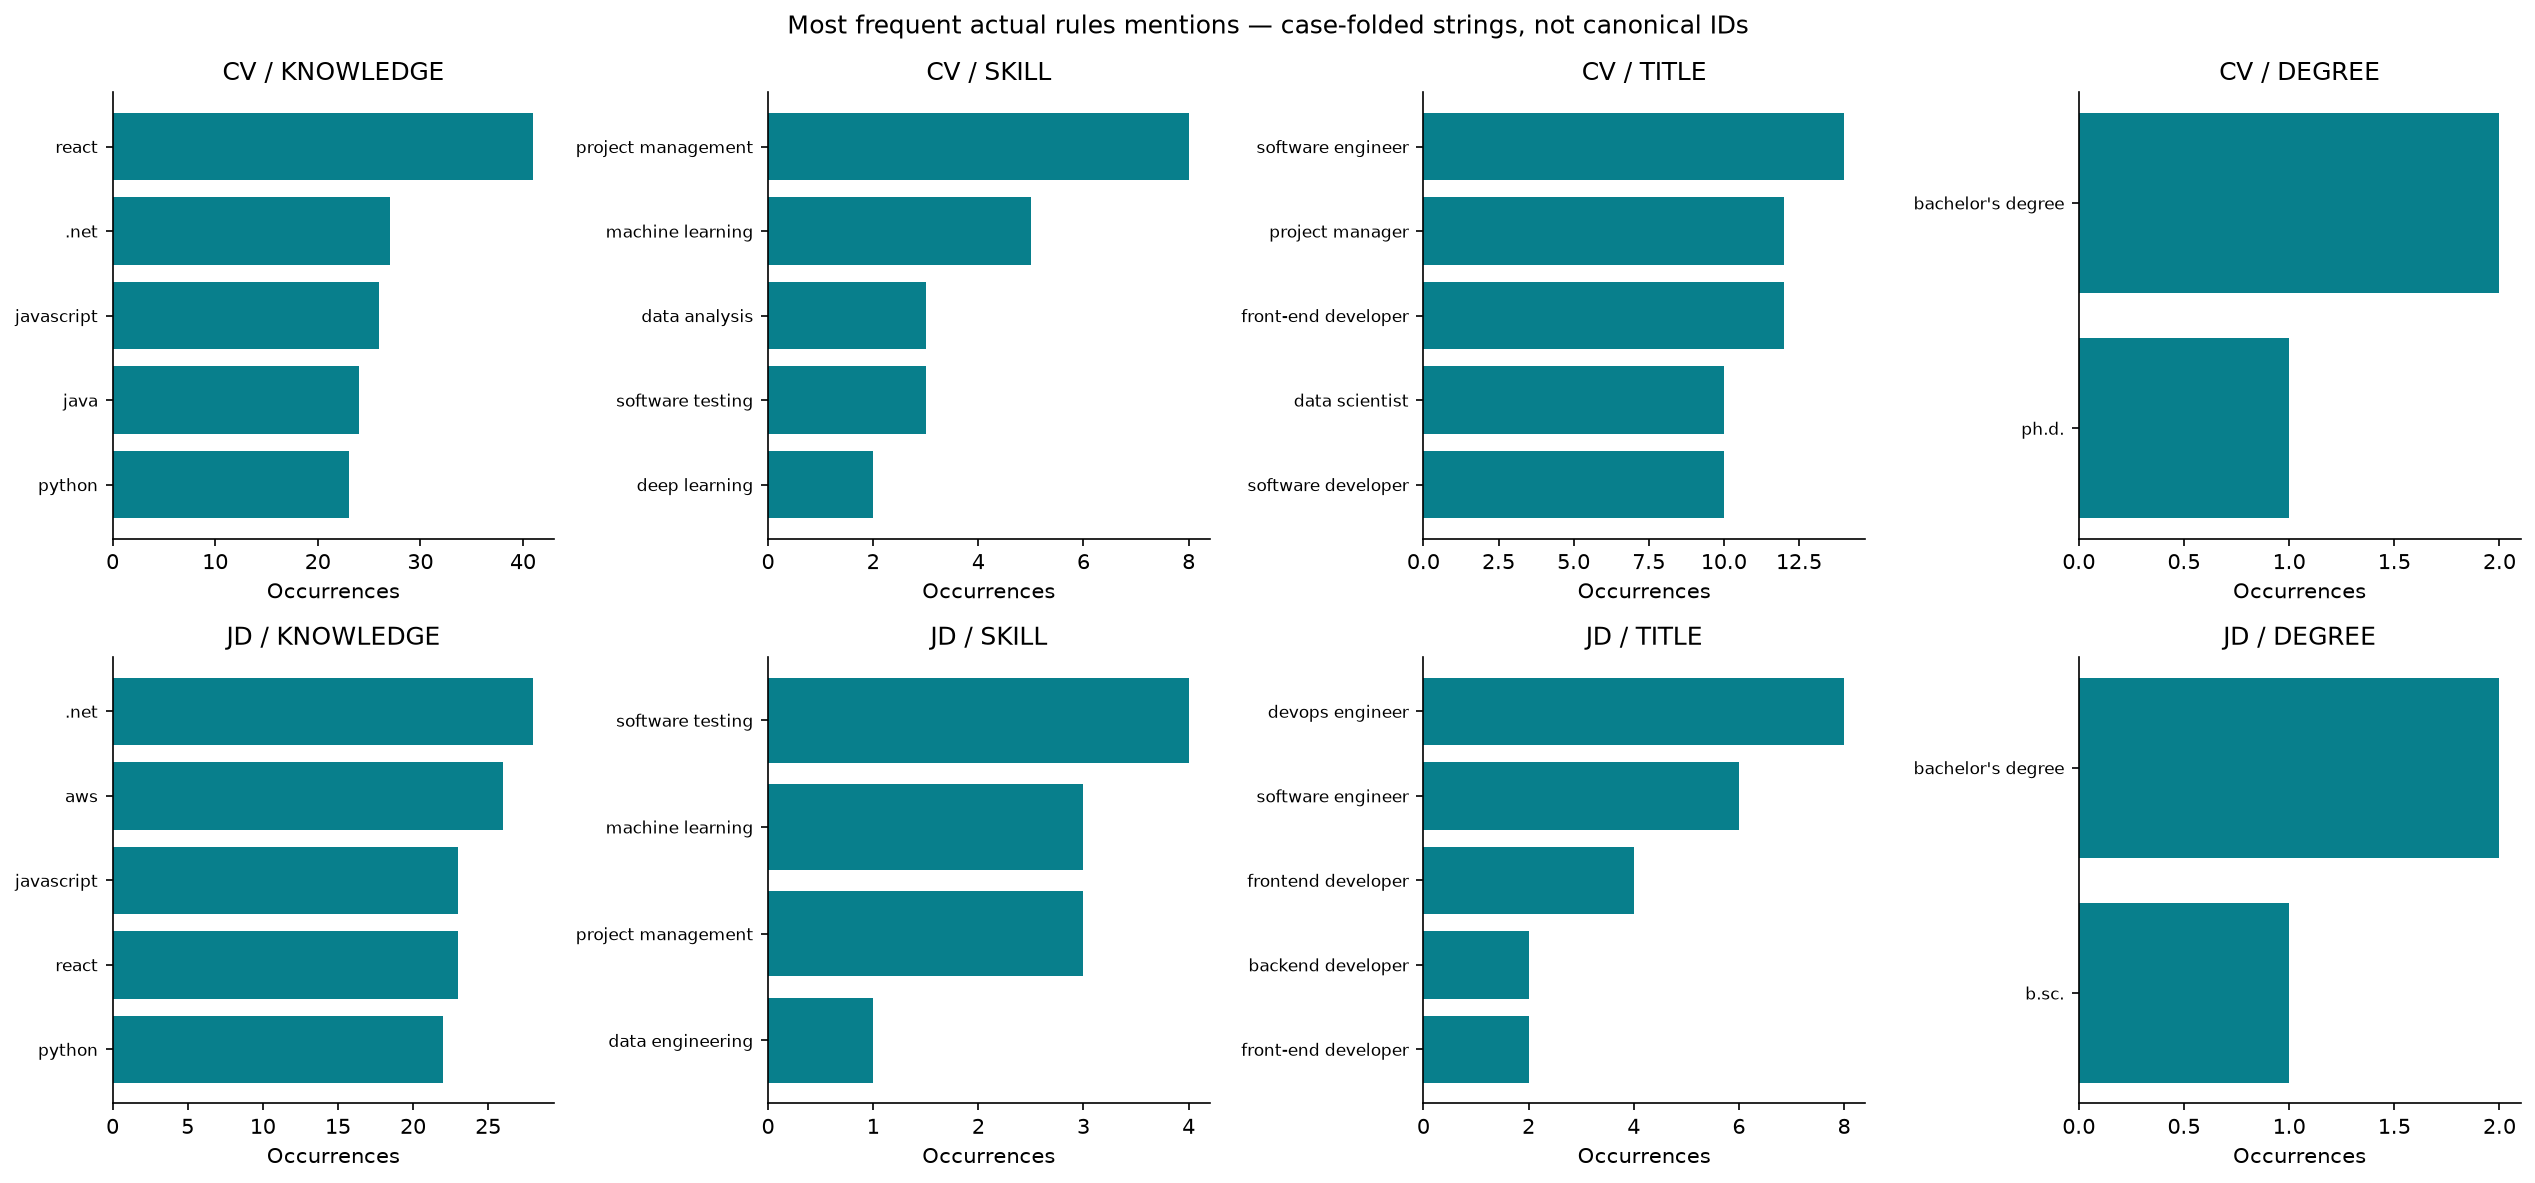

In [9]:
display(Image(filename=charts["mentions-rules"]))

## 5. Raw scores and threshold sensitivity

The stored output was extracted at **0.5**, so no conclusion can be drawn about predictions below that threshold. The score histogram is conditional on retention at 0.5. Post-hoc thresholds 0.5–0.9 filter saved spans without rerunning the model.

Higher thresholds reduce retained predictions and may change document coverage; these curves are **not precision estimates**, and no threshold is validated or tuned against human gold.

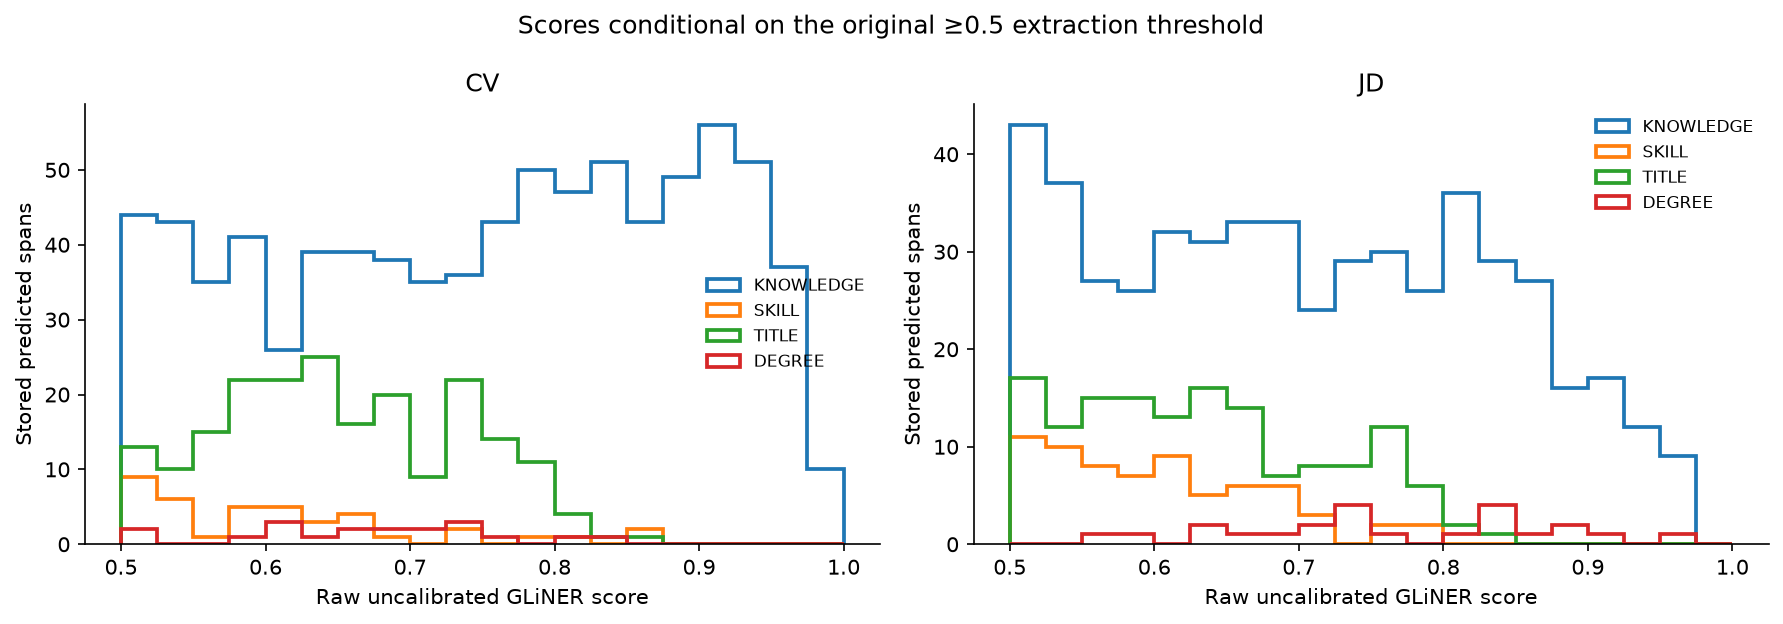

In [10]:
display(Image(filename=charts["scores"]))

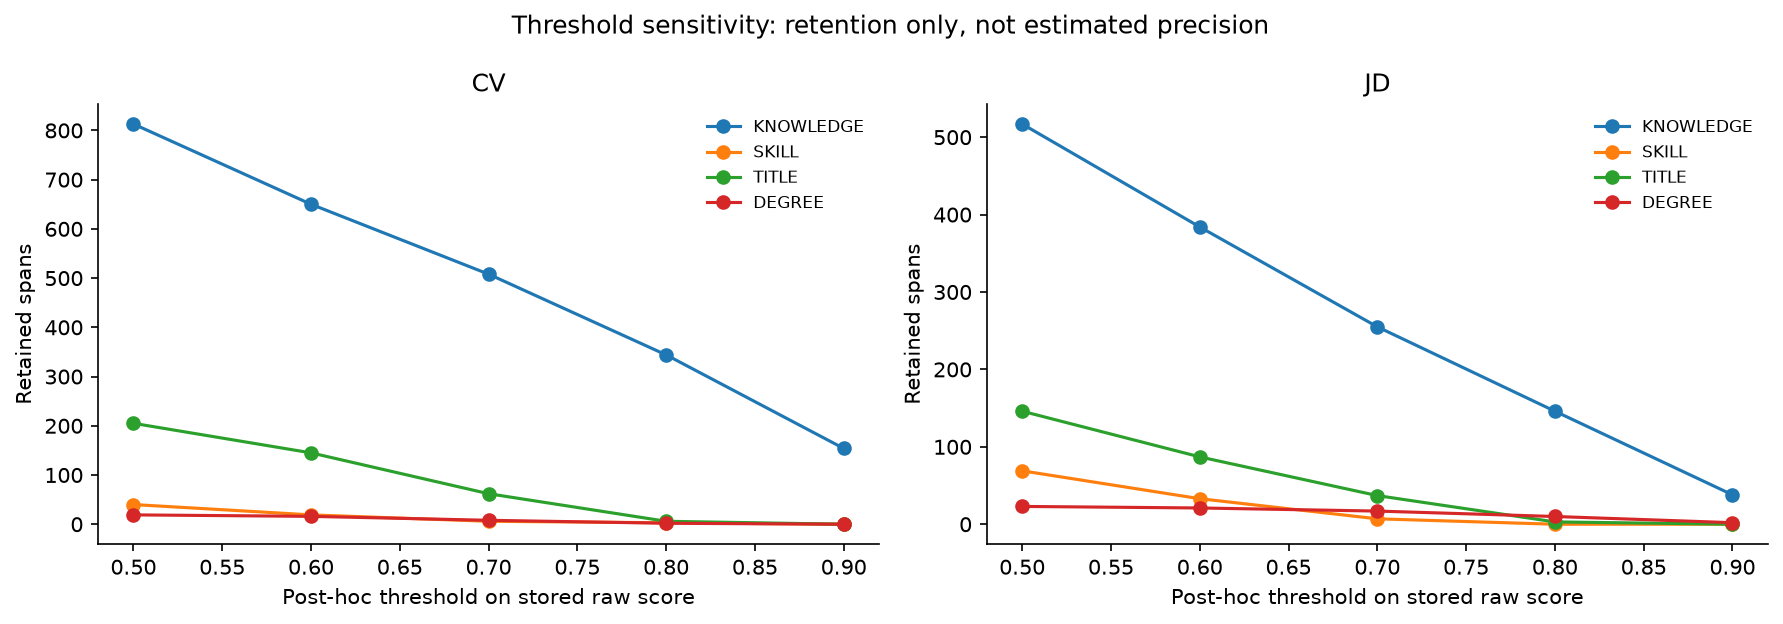

In [11]:
display(Image(filename=charts["thresholds"]))

## 6. Exact overlap and real disagreement examples

An exact shared prediction agrees on source, document, field, start, end and label. Partial spans, nested spans or identical strings at different positions are different predictions. The stacked bars use the distinct union of these keys; shared spans are counted once. Disagreement is not an error judgement.

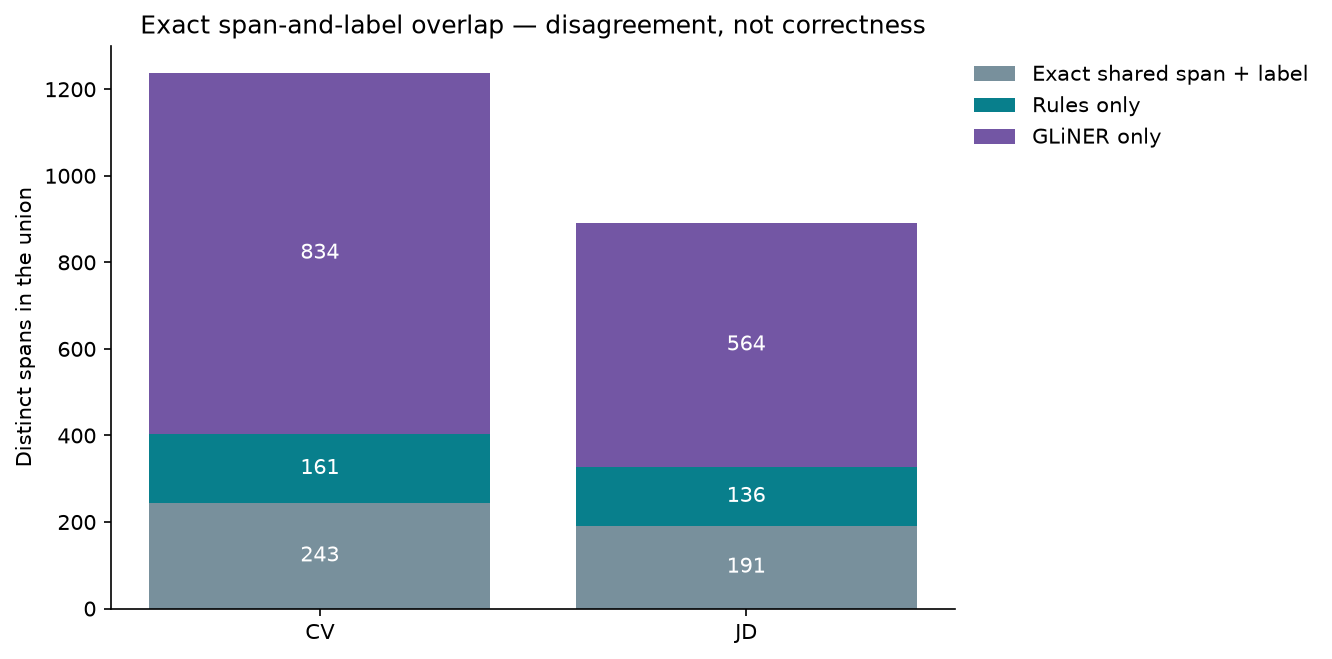

In [12]:
display(Image(filename=charts["overlap"]))

### Shared spans

Five actual examples at most, with short source context. Display contact redaction may alter surface/context strings, while coordinates continue to refer to the original local source field. These examples are inspection material, not gold judgements.

In [13]:
examples = bounded_examples(analysis, category="shared", limit=5, context_chars=60)
examples["surface"] = examples["surface"].map(redact_text)
examples["context"] = examples["context"].map(redact_text)
assert_clean(examples["surface"], "shared real entity surfaces")
assert_clean(examples["context"], "shared bounded contexts")
rendered = examples.to_json(orient="records", force_ascii=False)
assert len(examples) <= 5 and len(rendered) <= 1990
print(rendered)


[{"surface":"Project Manager","label":"TITLE","doc_type":"cv","field":"Position","start":0,"end":15,"context":"Project Manager"},{"surface":"front-end developer","label":"TITLE","doc_type":"cv","field":"Looking For","start":30,"end":49,"context":"I want to become an excellent front-end developer, return to IT, and regain sta"},{"surface":"React","label":"KNOWLEDGE","doc_type":"cv","field":"Moreinfo","start":108,"end":113,"context":"ology stack: HTML5, CSS3, JS, React, React Router, i18next, Helme"},{"surface":"React","label":"KNOWLEDGE","doc_type":"cv","field":"Moreinfo","start":115,"end":120,"context":"tack: HTML5, CSS3, JS, React, React Router, i18next, Helmet, AWS "},{"surface":"SQL","label":"KNOWLEDGE","doc_type":"cv","field":"Highlights","start":113,"end":116,"context":"70%\r\nSDLC              - 70%\r\nSQL                - 70%\r\nClient-"}]


### Rules-only spans

A seed match can disagree because the model omitted it, selected another boundary or chose another label. The examples alone cannot distinguish those possibilities from errors.

In [14]:
examples = bounded_examples(analysis, category="rule_only", limit=5, context_chars=60)
examples["surface"] = examples["surface"].map(redact_text)
examples["context"] = examples["context"].map(redact_text)
assert_clean(examples["surface"], "rules-only real entity surfaces")
assert_clean(examples["context"], "rules-only bounded contexts")
rendered = examples.to_json(orient="records", force_ascii=False)
assert len(examples) <= 5 and len(rendered) <= 1990
print(rendered)


[{"surface":"AWS","label":"KNOWLEDGE","doc_type":"cv","field":"Moreinfo","start":1262,"end":1265,"context":" for Blockchain-API usage \r\n- AWS (DynamoDB, S3 , and RDS) for "},{"surface":"AWS","label":"KNOWLEDGE","doc_type":"cv","field":"Moreinfo","start":146,"end":149,"context":"eact Router, i18next, Helmet, AWS S3, AWS SES\r\n\r\n- To Do List, "},{"surface":"AWS","label":"KNOWLEDGE","doc_type":"cv","field":"Moreinfo","start":154,"end":157,"context":"ter, i18next, Helmet, AWS S3, AWS SES\r\n\r\n- To Do List, which wo"},{"surface":"Front-end Developer","label":"TITLE","doc_type":"cv","field":"Position","start":7,"end":26,"context":"Junior Front-end Developer"},{"surface":"DevOps engineer","label":"TITLE","doc_type":"cv","field":"Position","start":7,"end":22,"context":"Senior DevOps engineer"}]


### Neural-only spans

These are real model surfaces, including phrases outside the seed vocabulary. Contact redaction is a limited safeguard, not a claim to remove personal names. No unreviewed span is silently converted into a canonical skill or positive screening evidence.

In [15]:
examples = bounded_examples(analysis, category="neural_only", limit=5, context_chars=60)
examples["surface"] = examples["surface"].map(redact_text)
examples["context"] = examples["context"].map(redact_text)
assert_clean(examples["surface"], "neural-only real entity surfaces")
assert_clean(examples["context"], "neural-only bounded contexts")
rendered = examples.to_json(orient="records", force_ascii=False)
assert len(examples) <= 5 and len(rendered) <= 1990
print(rendered)


[{"surface":"IT","label":"KNOWLEDGE","doc_type":"cv","field":"Looking For","start":52,"end":54,"context":"w and interesting projects in IT with good career growth. Want"},{"surface":"marketing automation","label":"KNOWLEDGE","doc_type":"cv","field":"Moreinfo","start":120,"end":140,"context":"cts of key marketing systems (marketing automation, CRM project with 2 PHP devel"},{"surface":"JIRA","label":"KNOWLEDGE","doc_type":"cv","field":"Moreinfo","start":348,"end":352,"context":"\tProcess and task management (JIRA, Wrike & Redmine);\r\n-\tWebsite"},{"surface":"proven leadership and organization skills","label":"SKILL","doc_type":"cv","field":"Moreinfo","start":596,"end":637,"context":"approvals.\r\n\r\nMain skills:\r\n- proven leadership and organization skills\r\n- teamwork and collaboration"},{"surface":"teamwork and collaboration","label":"SKILL","doc_type":"cv","field":"Moreinfo","start":641,"end":667,"context":"ip and organization skills\r\n- teamwork and collaboration \r\n- system 

## 7. Source fields, context and limits

The field chart counts spans by original source field. `Position` represents a profile/job title rather than full employment history, while CV `Looking For` represents aspiration. Context categories remain heuristic even for neural mentions; negation, learning and job required/preferred status are not solved by mention extraction alone.

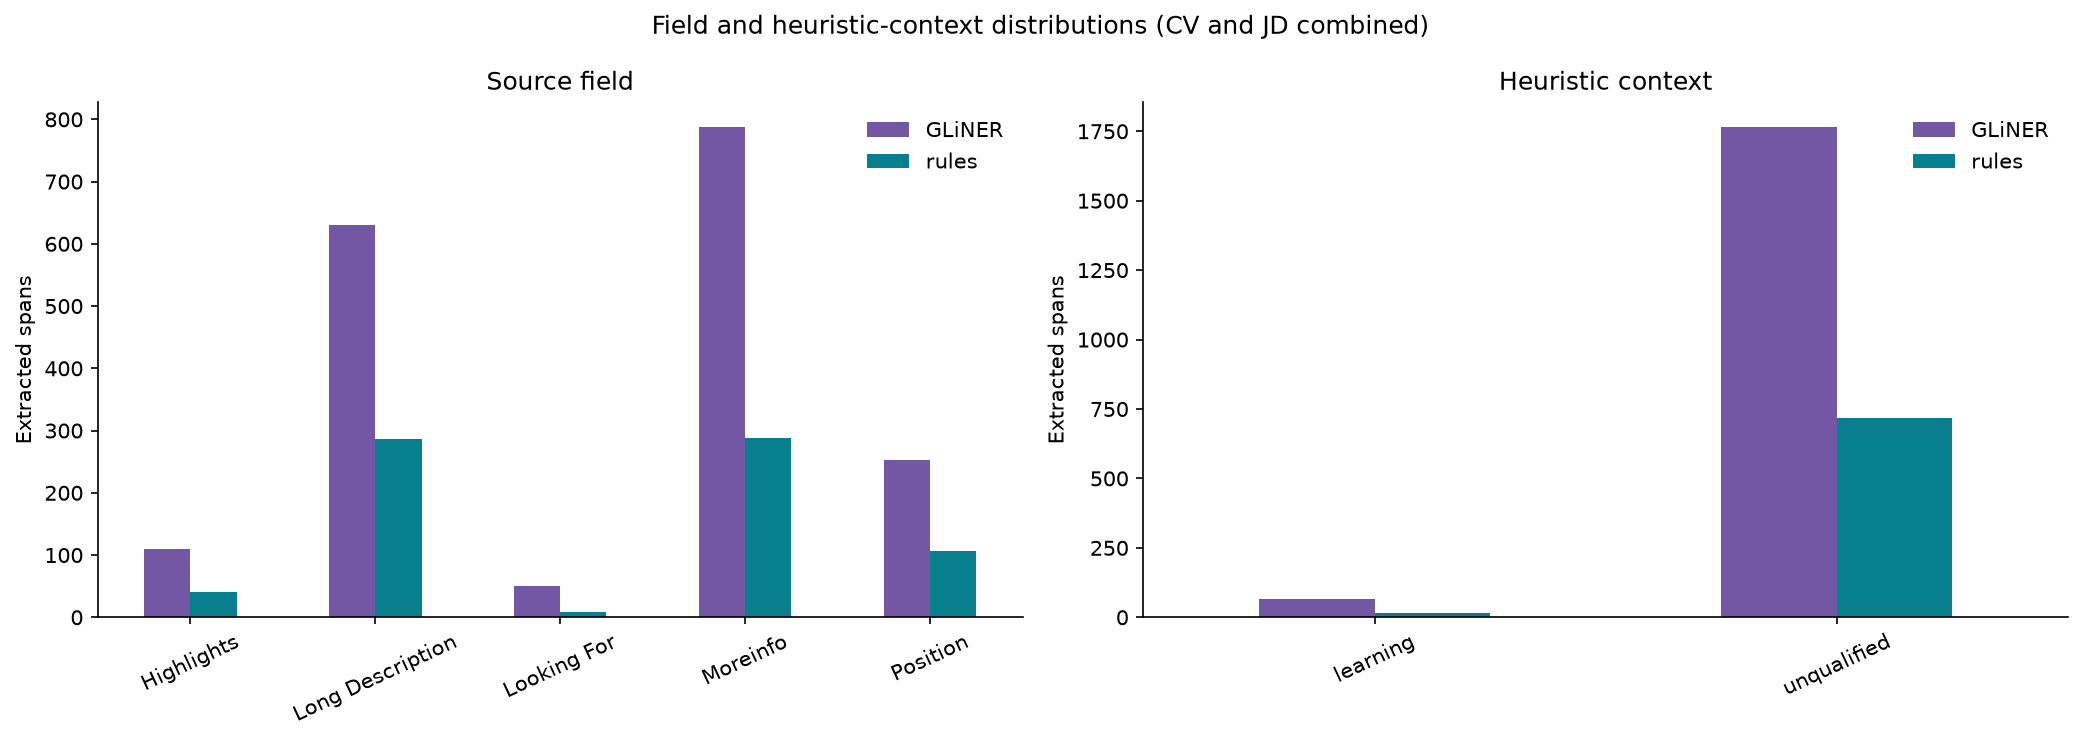

In [16]:
display(Image(filename=charts["field_context"]))

## Observed label ambiguities

The actual GLiNER frequency charts contain inspection cases worth checking before screening integration. `DEGREE` includes **upper intermediate**, **MCSA**, **exam 483** and **master of the self-education**; a language level or professional certification is not automatically an academic degree. The `SKILL` panel includes **back end developer** and **front end developer**, which also resemble job-title phrases. These are qualitative flags, not independently adjudicated errors or an error rate.

GLiNER returned at least one span for 100/100 CVs and 99/100 JDs; the rules returned spans for 74/100 CVs and 67/100 JDs. The broader neural coverage can include useful new vocabulary and ambiguous labels simultaneously. Review actual supporting context rather than treating confidence, coverage or total mention counts as proof of quality.


## Reading the measured findings

Both methods operate on one frozen training draw, and all source fields in the saved neural run were covered. GLiNER supplies more spans and broader title/qualification phrases; the rules provide a narrower, explicit vocabulary. Inspect frequencies, zero-document counts and exact disagreement before interpreting these differences as useful screening features.

The charts and aggregate tables are saved under `output/extraction/eda/`; real contextual examples remain notebook inspection outputs or ignored local records, never full document exports. No labelled extraction spans exist for this draw. Precision/recall/F1, canonical mapping accuracy and downstream Recall@10 improvement remain unmeasured. A later retrieval comparison must keep `generic` and `targeted` separate, with Precision@k's ceiling and the documented A13 uncertainty.